# **Section 8: Support Vector Machine**

In this notebook, I will train and evaluate Support Vector Machine (SVM) models. I will start with a basic SVM with default parameters, and will then tune the regularization parameter (C) and kernel type using a cross-validated grid search.

#### **Contents**
1. **Import data**
2. **Basic decision tree**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Saving model results**

## **1. Importing the Data**

Let's import the training and test datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

# Set pastel color palette for plots
sns.set_palette("pastel")

In [2]:
# Load features and labels
snp_train = pd.read_csv("Data/snp_train_selected.csv", index_col=0)
snp_test = pd.read_csv("Data/snp_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = snp_train.values
y_train = profiles_train.values

X_test = snp_test.values
y_test = profiles_test.values

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (176, 796)
Test set shape: (50, 796)
Categories: [0 1]


## **2. Basic Support Vector Machine**

### **2.1 Fit and train the model**
Let's start with a basic SVM using default parameters (linear kernel, C=1.0).

In [3]:
# Create SVM pipeline with standardization
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel='linear', C=1.0, random_state=2)
)

# Train the model
svm.fit(X_train, y_train)
print("SVM model trained")

SVM model trained


### **2.2 Evaluate model**

In [4]:
# Evaluate on training, validation, and test sets
accuracy_train = svm.score(X_train, y_train)
accuracy_test = svm.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.9943
Accuracy test set: 0.5000


### **2.3 Classification Report and Confusion Matrix**

In [5]:
# Get predictions
y_test_pred = svm.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.27      0.39        30
           1       0.44      0.85      0.58        20

    accuracy                           0.50        50
   macro avg       0.58      0.56      0.48        50
weighted avg       0.61      0.50      0.46        50



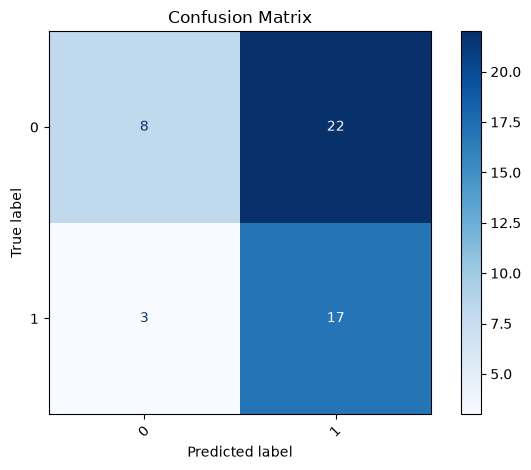

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=svm.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=svm.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

This basic model already performs quite well. Also performs poorly, which is now to be expected.

## **3. Hyperparameter tuning**

Now let's use cross-validated grid search to find the optimal regularization parameter (C) and kernel type.

### **3.1 Grid Search for Optimal Hyperparameters**

In [7]:
# Create SVM pipeline for grid search
svm_pipeline = make_pipeline(
    StandardScaler(),
    SVC(random_state=1, probability=True)
)

# Define parameter grid
param_grid = {
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__C': np.logspace(-3, 4, 8)  # 0.001 to 100
}

# Create grid search object
grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=5,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")


Best parameters: {'svc__C': np.float64(100.0), 'svc__kernel': 'rbf'}
Best cross-validation score: 0.7835


In [8]:
# Extract results
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score', 
    'mean_train_score', 'std_train_score',
    'param_svc__kernel', 'param_svc__C'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.721905        0.066911          0.839524         0.019093   
1         0.585238        0.012813          0.585228         0.003181   
2         0.585238        0.012813          0.585228         0.003181   
3         0.721905        0.056311          0.934640         0.007154   
4         0.585238        0.012813          0.585228         0.003181   

  param_svc__kernel  param_svc__C  
0            linear         0.001  
1               rbf         0.001  
2              poly         0.001  
3            linear         0.010  
4               rbf         0.010  


### **3.2 Training and validation curves**

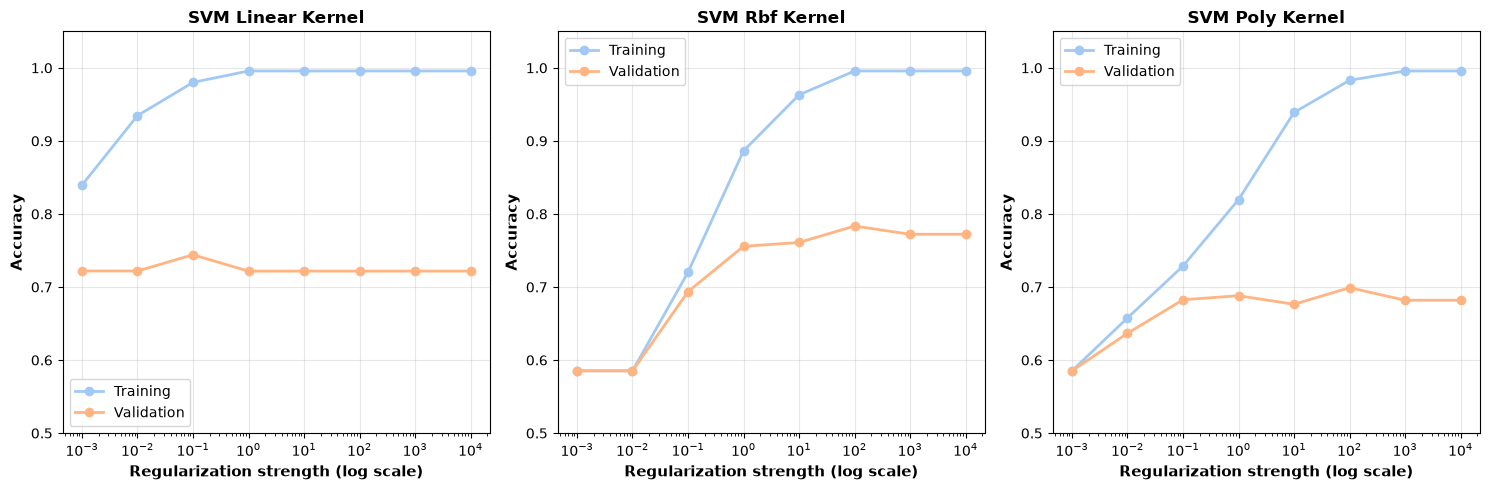

In [9]:
# Separate results by kernel
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
kernels = ['linear', 'rbf', 'poly']

for idx, kernel in enumerate(kernels):
    kernel_results = cv_results[cv_results['param_svc__kernel'] == kernel].sort_values('param_svc__C')
    
    axes[idx].semilogx(kernel_results['param_svc__C'], kernel_results['mean_train_score'], label='Training', marker='o', linewidth=2)
    axes[idx].semilogx(kernel_results['param_svc__C'], kernel_results['mean_test_score'], label='Validation', marker='o', linewidth=2)
    
    axes[idx].set_xlabel('Regularization strength (log scale)', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Accuracy', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'SVM {kernel.capitalize()} Kernel', fontsize=12, fontweight='bold')
    axes[idx].legend(fontsize=10)
    axes[idx].grid(alpha=0.3)
    axes[idx].set_ylim([0.5, 1.05])

plt.tight_layout()
plt.savefig("Figures/06_svm_training_curve", dpi=300)
plt.show()

We see that the poly kernel with a regularization strength of 100 or more performs the best on the validation set. 

## **4. Evaluate Best Model**
### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_svm = grid_search.best_estimator_
accuracy_test_best = best_svm.score(X_test, y_test)

print(f"\nBest Model Test Accuracy: {accuracy_test_best:.4f}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")


Best Model Test Accuracy: 0.4400
Best parameters: {'svc__C': np.float64(100.0), 'svc__kernel': 'rbf'}
Best CV score: 0.7835


### **4.2 Classification Report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_svm.predict(X_test)

# Classification report
print("\nClassification Report (Best SVM):")
print(classification_report(y_test, y_test_pred_best))


Classification Report (Best SVM):
              precision    recall  f1-score   support

           0       0.55      0.37      0.44        30
           1       0.37      0.55      0.44        20

    accuracy                           0.44        50
   macro avg       0.46      0.46      0.44        50
weighted avg       0.48      0.44      0.44        50



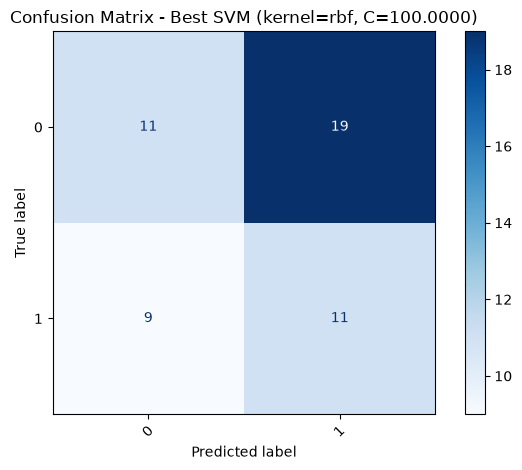

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_svm.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_svm.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix - Best SVM (kernel={grid_search.best_params_['svc__kernel']}, C={grid_search.best_params_['svc__C']:.4f})")
plt.tight_layout()
plt.savefig("Figures/06_svm_cm", dpi=300)
plt.show()

Nothing more to say here a part from the fact that the models performing so poorly likely comes from the data, and not the models.

### **4.3 ROC curve and AUC score**

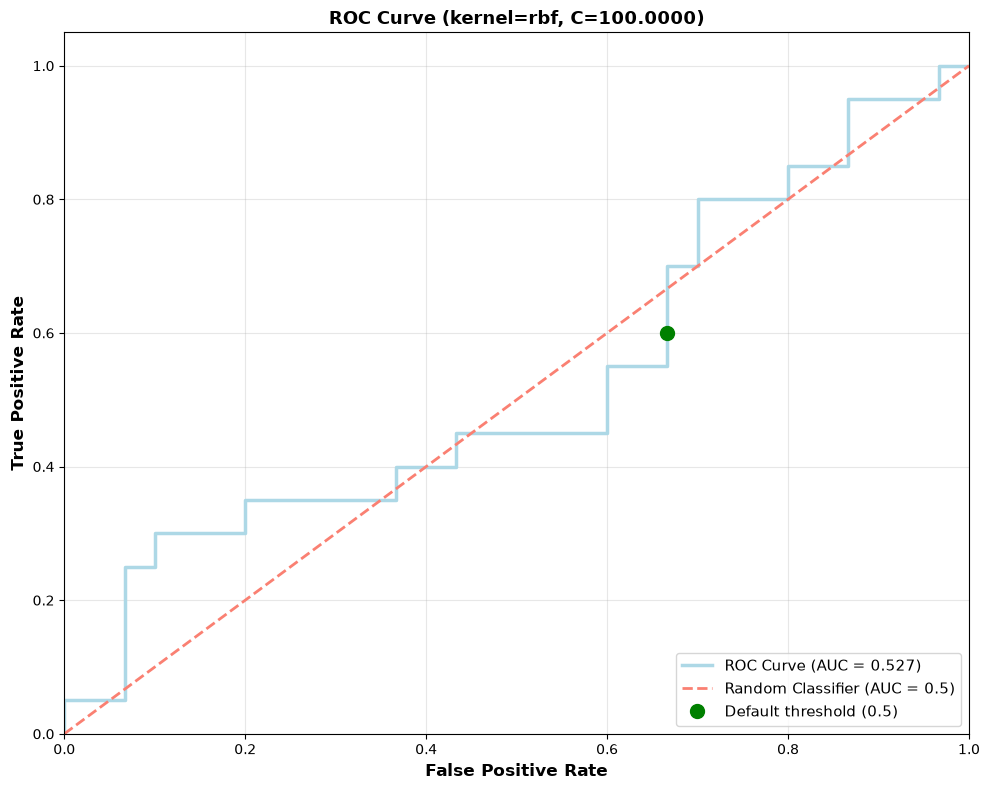


AUC Score: 0.5267
At the default threshold (0.5):
True positive rate: 0.600 (60.0% of resistant correctly classified)
False positive rate: 0.667 (66.7% of susceptible wrongly classified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_svm.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba, drop_intermediate = False)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='lightblue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='salmon', lw=2, linestyle='--', label='Random Classifier (AUC = 0.5)')

# Mark the default threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (kernel={grid_search.best_params_["svc__kernel"]}, C={grid_search.best_params_["svc__C"]:.4f})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/06_svm_ROC", dpi=300)
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At the default threshold (0.5):")
print(f"True positive rate: {tpr[default_idx]:.3f} ({tpr[default_idx]*100:.1f}% of resistant correctly classified)")
print(f"False positive rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptible wrongly classified)")

## **5. Save Results**

In [14]:
import csv
import os

# Store results
results = {
    'model': 'Support Vector Machine',
    'hyperparameters': f"kernel={grid_search.best_params_['svc__kernel']}, C={grid_search.best_params_['svc__C']:.4f}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = 'Results/model_results.csv'

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"  Model: {results['model']}")
print(f"  Hyperparameters: {results['hyperparameters']}")
print(f"  Test Accuracy: {results['test_accuracy']:.4f}")
print(f"  CV Score: {results['cv_score']:.4f}")


Results saved:
  Model: Support Vector Machine
  Hyperparameters: kernel=rbf, C=100.0000
  Test Accuracy: 0.4400
  CV Score: 0.7835
